In [1]:
import textwrap

import fcbench
import numpy as np
import pandas as pd
import xarray as xr

from matplotlib import pyplot as plt
from tqdm import tqdm

In [2]:
ds_500hPa_mean = xr.open_dataset("data/500hPa-mean.nc", chunks={})
ds_500hPa_spread = xr.open_dataset("data/500hPa-spread.nc", chunks={})

In [3]:
ds_1000hPa_mean = xr.open_dataset("data/1000hPa-mean.nc", chunks={})
ds_1000hPa_spread = xr.open_dataset("data/1000hPa-spread.nc", chunks={})

In [4]:
ds_depth_mean = xr.open_dataset("data/depth-mean.nc", chunks={})
ds_depth_spread = xr.open_dataset("data/depth-spread.nc", chunks={})

In [5]:
ds_surface_mean = xr.open_dataset("data/surface-mean.nc", chunks={})
ds_surface_spread = xr.open_dataset("data/surface-spread.nc", chunks={})

In [6]:
ds_mean = xr.Dataset({
    **{v: da.squeeze().drop_vars("pressure_level").assign_attrs(long_name=f"{da.long_name} (500 hPa)") for v, da in ds_500hPa_mean.items()},
    **{v: da.squeeze().drop_vars("pressure_level").assign_attrs(long_name=f"{da.long_name} (1000 hPa)") for v, da in ds_1000hPa_mean.items()},
    **ds_depth_mean,
    **ds_surface_mean,
})
ds_spread = xr.Dataset({
    **{v: da.squeeze().drop_vars("pressure_level").assign_attrs(long_name=f"{da.long_name} (500 hPa)") for v, da in ds_500hPa_spread.items()},
    **{v: da.squeeze().drop_vars("pressure_level").assign_attrs(long_name=f"{da.long_name} (1000 hPa)") for v, da in ds_1000hPa_spread.items()},
    **ds_depth_spread,
    **ds_surface_spread,
})

In [7]:
list(ds_mean)

['z',
 'q',
 'r',
 'swvl1',
 'siconc',
 'lai_hv',
 'sp',
 'sd',
 'lsp',
 'cp',
 'tcc',
 'u10',
 'v10',
 't2m',
 'ssrd',
 'src',
 'tco3',
 'cbh']

In [8]:
def plot_ensemble_mean_spread(key, ax, sample=slice(None)):
    mean = ds_mean[key]
    spread = ds_spread[key]

    months = sorted(set(zip(
        pd.to_datetime(mean.valid_time).year,
        pd.to_datetime(mean.valid_time).month,
    )))
    colours = ["tab:orange", "tab:blue"]
    
    ax.set_title(f"{'\n'.join(textwrap.wrap(mean.long_name, width=22, break_long_words=False))}")
    ax.set_xlabel(f"mean [{mean.units}]")
    ax.set_ylabel(f"spread [{spread.units}]")

    if key in ():
        ax.set_xscale("log")
        ax.set_yscale("log")

    handles = []

    for (year, month), colour in zip(months, colours):
        handles.append(ax.scatter(
            mean.sel(valid_time=f"{year}-{month:02}").values.flatten()[sample],
            spread.sel(valid_time=f"{year}-{month:02}").values.flatten()[sample],
            s=1, label=f"{year}/{month:02}", edgecolor="none", marker=".", c=colour,
        ))

    return handles

100%|███████████████████████████████████████████████████████████████████████████████| 18/18 [00:44<00:00,  2.49s/it]


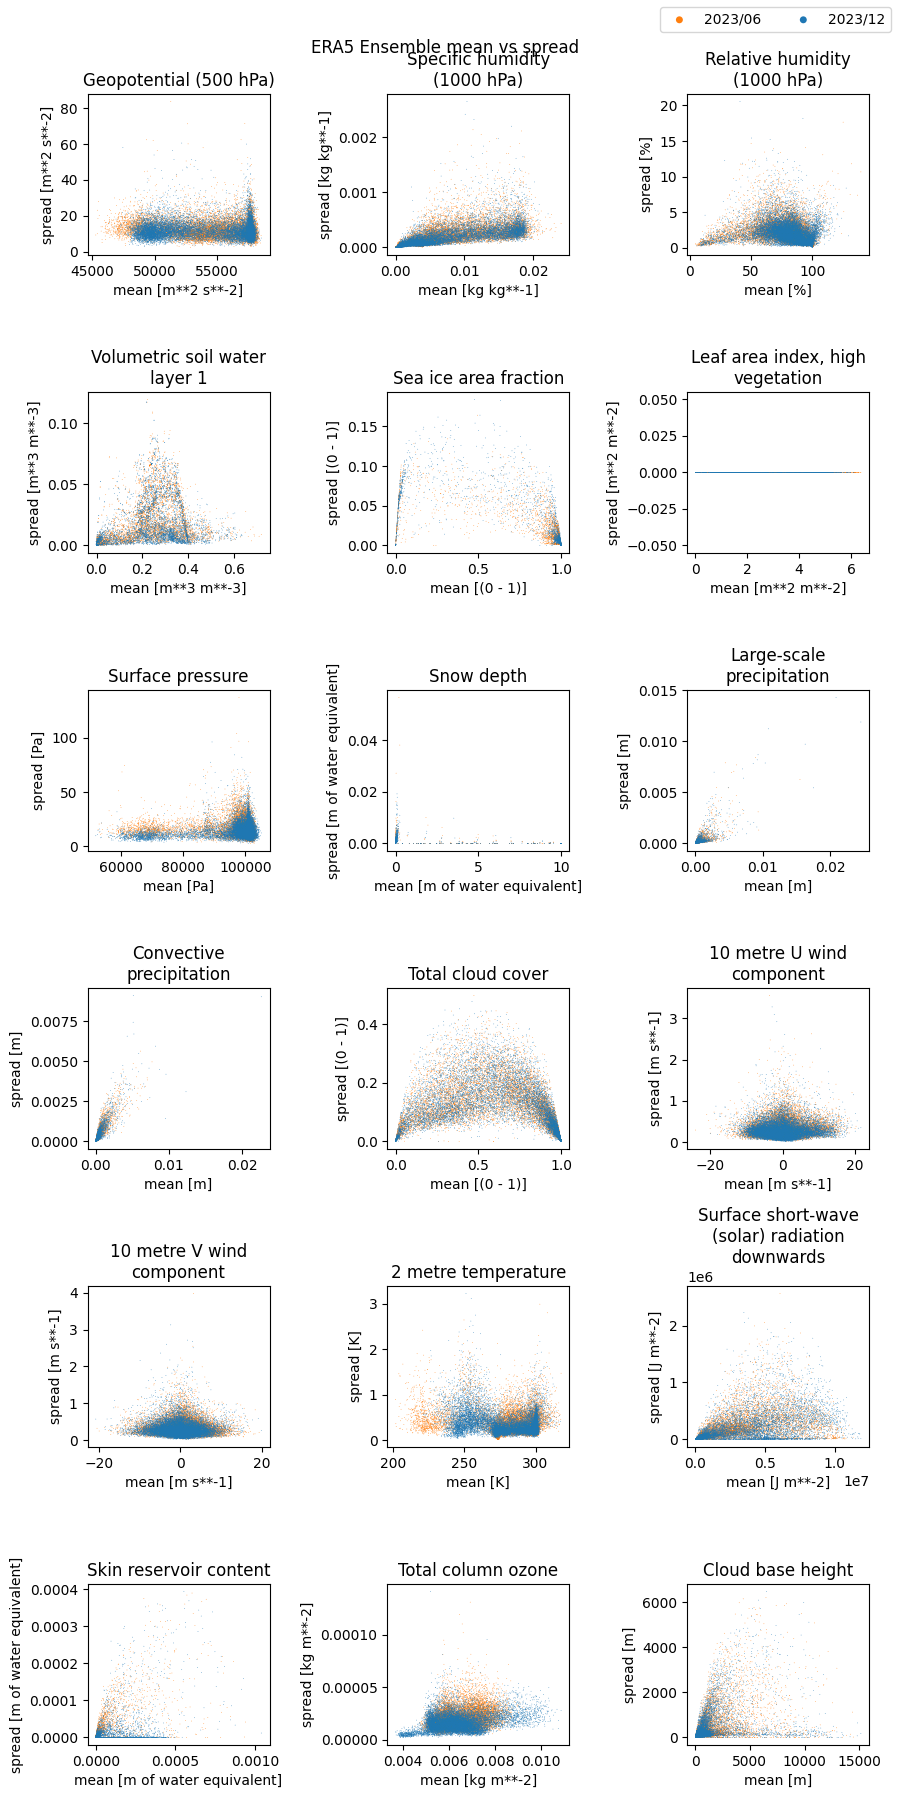

In [9]:
fig, axs = plt.subplots(6, 3, figsize=(9, 18))
fig.suptitle("ERA5 Ensemble mean vs spread")

for key, ax in zip(tqdm(ds_mean), axs.flatten()):
    handles = plot_ensemble_mean_spread(key, ax, sample=slice(0, None, 5000))

fig.legend(handles=handles, loc="upper right", ncols=len(handles), markerscale=10)

fig.tight_layout()
plt.show()

In [10]:
def plot_bitinformation(key, ax):
    mean = ds_mean[key]

    months = sorted(set(zip(
        pd.to_datetime(mean.valid_time).year,
        pd.to_datetime(mean.valid_time).month,
    )))
    colours = ["tab:orange", "tab:blue"]
    
    ax.set_title(f"{'\n'.join(textwrap.wrap(mean.long_name, width=22, break_long_words=False))}")
    
    ax.set_xlabel("bit index")
    ax.set_xticks([0, 8.5, 31])
    ax.set_ylabel("information [bits]")

    handles = []

    for (year, month), colour in zip(months, colours):
        bit_information = fcbench.metrics.BitInformation.bit_information(
            mean.sel(valid_time=f"{year}-{month:02}"),
            set_zero_insignificant_confidence=0.99,
        )

        p99 = np.searchsorted(np.cumsum(bit_information) / np.sum(bit_information), 0.99)
        ax.axvline(p99, c=colour, ls=":")
        
        handles.extend(ax.plot(
            np.arange(32), bit_information, label=f"{year}/{month:02}", c=colour,
        ))

    ax.axvline(8.5, c="black", ls="--")

    return handles

100%|███████████████████████████████████████████████████████████████████████████████| 18/18 [01:13<00:00,  4.07s/it]


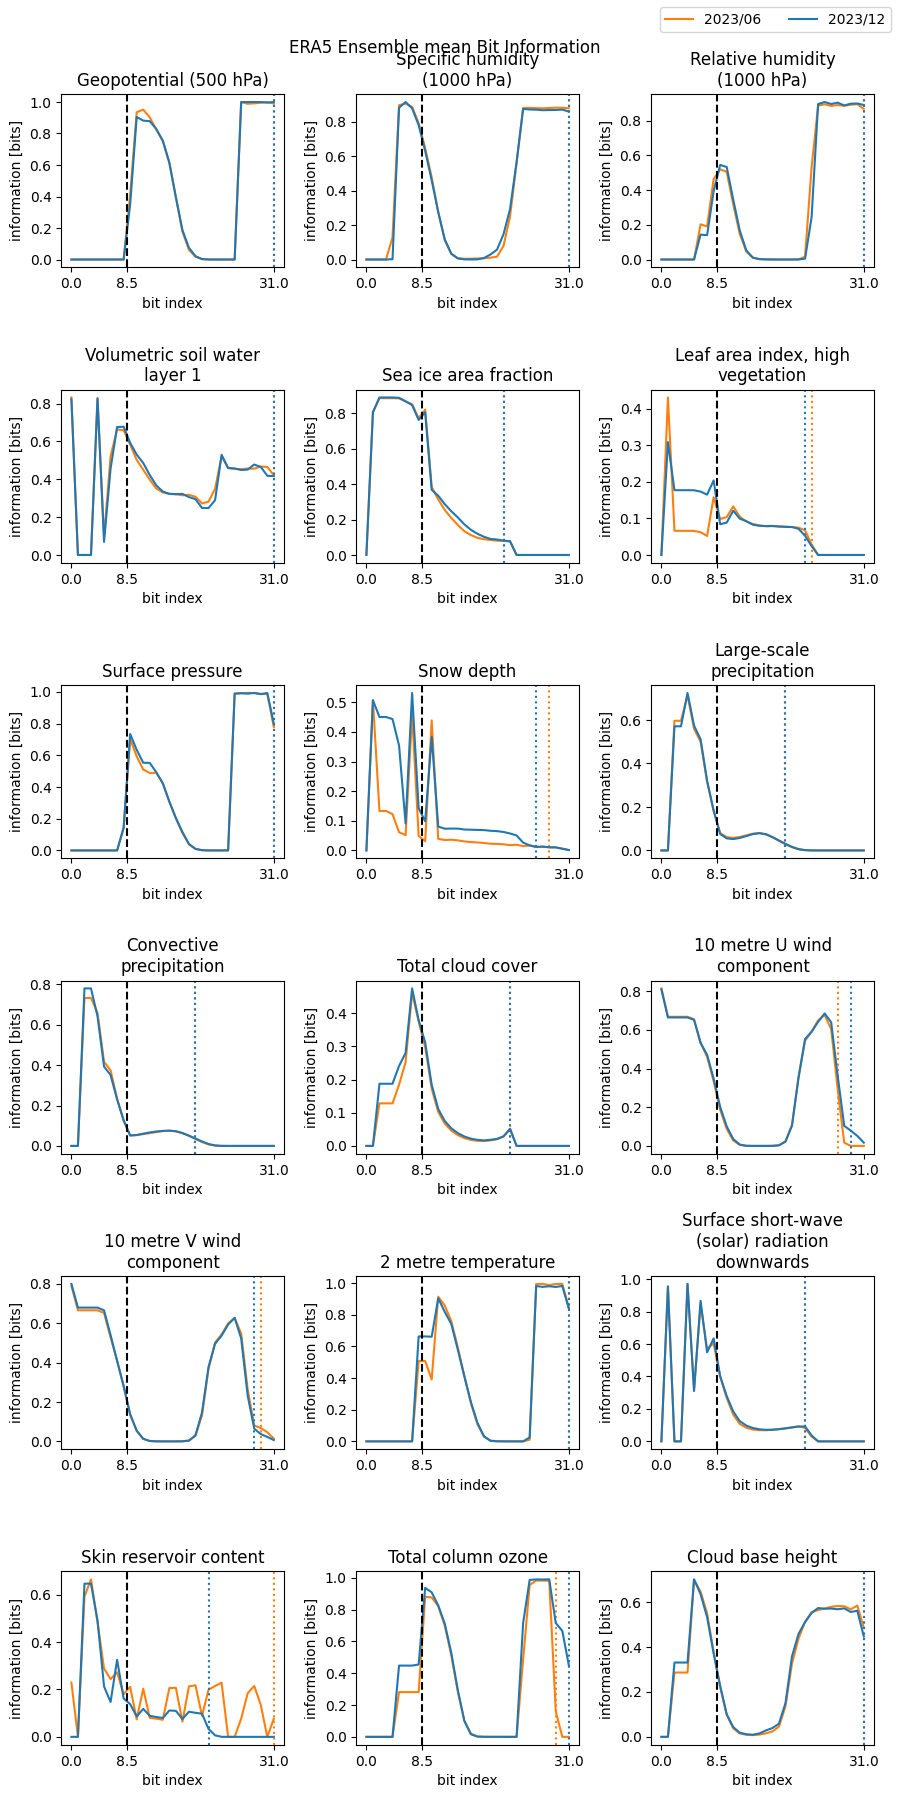

In [11]:
fig, axs = plt.subplots(6, 3, figsize=(9, 18))
fig.suptitle("ERA5 Ensemble mean Bit Information")

for key, ax in zip(tqdm(ds_mean), axs.flatten()):
    handles = plot_bitinformation(key, ax)

fig.legend(handles=handles, loc="upper right", ncols=len(handles))

fig.tight_layout()
plt.show()